# 02 - Análisis Exploratorio Visual

## 1. Carga

In [ ]:
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = PROJECT_DIR / "data" / "processed"
FRAMES_DIR = PROC / "frames"
FIG = PROJECT_DIR / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

video_meta = pd.read_csv(PROC / "video_meta.csv")
clip_index = pd.read_csv(PROC / "clip_index.csv")
events = pd.read_csv(PROC / "events.csv")
frames_index = pd.read_csv(PROC / "frames_index.csv")

POINT = ["play", "throwin", "challenge"]
PALETTE = {"bg": "#9aa0a6", "play": "#1a73e8", "throwin": "#f9ab00", "challenge": "#d93025"}

print("frames muestreados:", len(frames_index))
print("videos con footage:", sorted(frames_index.video_id.unique()))
frames_index.head()

frames muestreados: 9133
videos con footage: ['1606b0e6_0', '1606b0e6_1', '35bd9041_0']


,video_id,time_s,label,path
0,1606b0e6_0,0.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
1,1606b0e6_0,10.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
2,1606b0e6_0,20.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
3,1606b0e6_0,30.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
4,1606b0e6_0,40.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...


## 2. Metadata técnica del video

In [ ]:
cols = [c for c in ["video_id","has_video","n_clips","fps","width","height",
                    "aspect_ratio","clip_dur_s","approx_video_dur_s","annot_time_max_s"]
        if c in video_meta.columns]
disp = video_meta[video_meta.has_video][cols]
print(disp.to_string(index=False))

print("\n-- Homogeneidad --")
for col in ["fps", "width", "height", "aspect_ratio", "clip_dur_s"]:
    if col in video_meta.columns:
        print(f"  {col:14s}: {sorted(video_meta.loc[video_meta.has_video, col].dropna().unique())}")

if "clip_dur_s" in video_meta.columns:
    d = video_meta.loc[video_meta.has_video, "clip_dur_s"].dropna()
    print(f"\nDuración real del primer clip por video: media {d.mean():.2f}s (supuesto: 30.0s)")

  video_id  has_video  n_clips  fps  width  height  aspect_ratio  clip_dur_s  approx_video_dur_s  annot_time_max_s
1606b0e6_0       True       76 25.0 1920.0  1080.0        1.7778        30.0              2280.0            3014.7
1606b0e6_1       True       92 25.0 1920.0  1080.0        1.7778        30.0              2760.0            3387.7
35bd9041_0       True       83 25.0 1920.0  1080.0        1.7778        30.0              2490.0            3061.9
35bd9041_1       True       93 25.0 1920.0  1080.0        1.7778        30.0              2790.0            3477.7
3c993bd2_0       True       81 25.0 1920.0  1080.0        1.7778        30.0              2430.0            2999.0

-- Homogeneidad --
  fps           : [np.float64(25.0)]
  width         : [np.float64(1920.0)]
  height        : [np.float64(1080.0)]
  aspect_ratio  : [np.float64(1.7778)]
  clip_dur_s    : [np.float64(30.0)]

Duración real del primer clip por video: media 30.00s (supuesto: 30.0s)


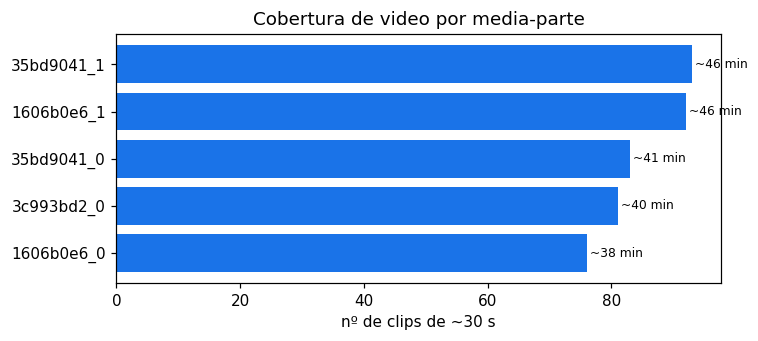

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
m = video_meta[video_meta.has_video].sort_values("n_clips")
ax.barh(m.video_id, m.n_clips, color="#1a73e8")
ax.set_xlabel("nº de clips de ~30 s"); ax.set_title("Cobertura de video por media-parte")
for i, v in enumerate(m.n_clips):
    ax.text(v + 0.5, i, f"~{v*30//60} min", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "01_cobertura_video.png"); plt.show()

## 3. Frames muestreados por clase

`bg` = frame de contexto (1 cada 10 s); el resto = ventana de ±2 s de un evento puntual.

              n     %
label                
play       7142  78.2
challenge  1051  11.5
bg          657   7.2
throwin     283   3.1

Por video:
 label        bg  play  throwin  challenge
video_id                                 
1606b0e6_0  204  1989      128        390
1606b0e6_1  232  2794       92        368
35bd9041_0  221  2359       63        293


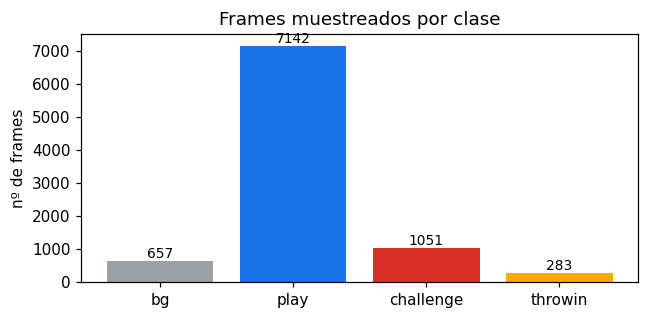

In [ ]:
by_label = frames_index.label.value_counts().rename("n")
by_label_pct = (by_label / by_label.sum() * 100).round(1).rename("%")
print(pd.concat([by_label, by_label_pct], axis=1))

tab = (frames_index.groupby(["video_id", "label"]).size()
       .unstack(fill_value=0)[["bg"] + [x for x in POINT if x in frames_index.label.unique()]])
print("\nPor video:\n", tab)

fig, ax = plt.subplots(figsize=(6, 3))
order = [l for l in ["bg","play","challenge","throwin"] if l in by_label.index]
ax.bar(order, by_label[order], color=[PALETTE[l] for l in order])
ax.set_ylabel("nº de frames"); ax.set_title("Frames muestreados por clase")
for i, l in enumerate(order):
    ax.text(i, by_label[l], f"{by_label[l]}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "02_frames_por_clase.png"); plt.show()

## 4. Propiedades de imagen

Por frame (imagen a 320 px): brillo, contraste, saturación, `green_ratio` (fracción de
píxeles verdes) y densidad de bordes (Canny).

In [ ]:
GREEN_LO = np.array([35, 40, 40]); GREEN_HI = np.array([85, 255, 255])

def frame_metrics(path):
    img = cv2.imread(str(PROJECT_DIR / path))
    if img is None:
        return None
    h, w = img.shape[:2]
    img = cv2.resize(img, (320, int(320 * h / w)))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, GREEN_LO, GREEN_HI)
    edges = cv2.Canny(gray, 100, 200)
    return {
        "brillo": float(gray.mean()),
        "contraste": float(gray.std()),
        "saturacion": float(hsv[..., 1].mean()),
        "green_ratio": float((green > 0).mean()),
        "edge_density": float((edges > 0).mean()),
    }

rows = []
for r in frames_index.itertuples(index=False):
    m = frame_metrics(r.path)
    if m:
        m.update(video_id=r.video_id, time_s=r.time_s, label=r.label, path=r.path)
        rows.append(m)
fm = pd.DataFrame(rows)
fm.to_csv(PROC / "frame_metrics.csv", index=False)
print(fm.shape, "| frames ilegibles:", len(frames_index) - len(fm))
fm.describe().round(3)

(9133, 9) | frames ilegibles: 0


,brillo,contraste,saturacion,green_ratio,edge_density,time_s
count,9133.000,9133.000,9133.000,9133.000,9133.000,9133.000
mean,108.300,36.245,127.067,0.748,0.103,1378.910
std,9.104,6.982,24.144,0.112,0.028,697.996
min,79.273,22.061,75.723,0.234,0.021,0.000
25%,104.930,30.796,100.187,0.716,0.084,785.900
50%,110.703,34.450,133.874,0.770,0.099,1302.900
75%,114.214,40.505,147.600,0.816,0.117,2004.900
max,125.114,66.271,173.867,0.973,0.205,2759.700


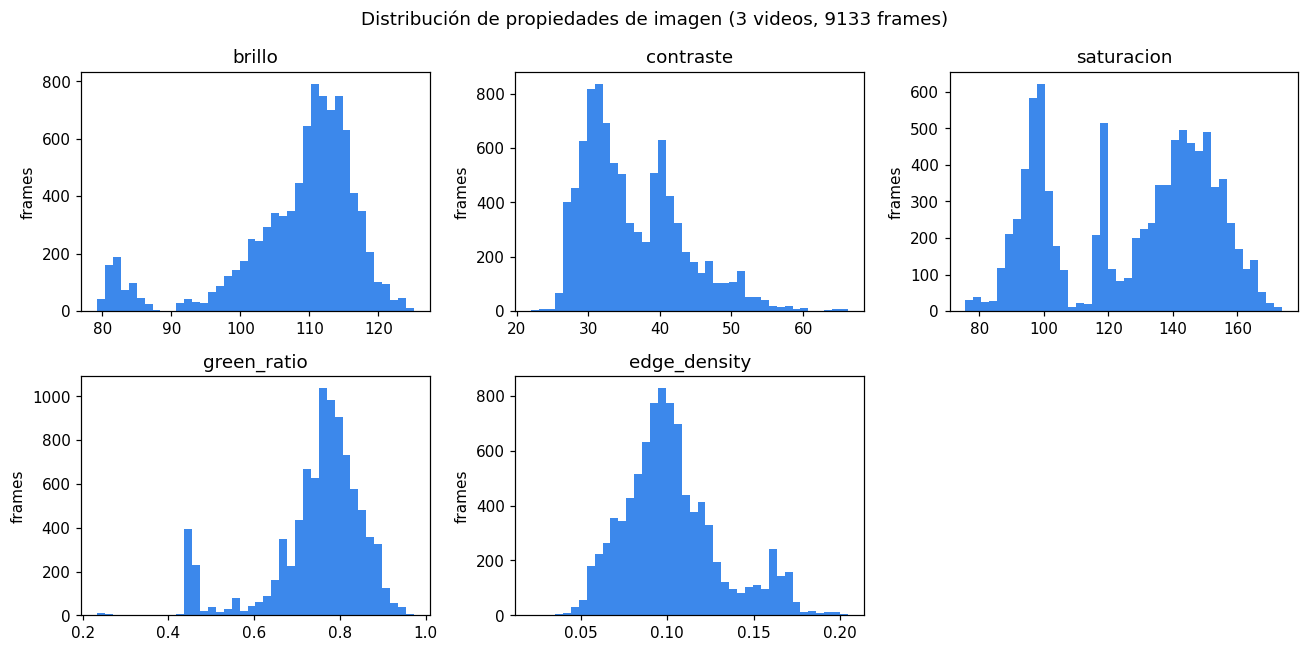

In [ ]:
metrics = ["brillo", "contraste", "saturacion", "green_ratio", "edge_density"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, met in zip(axes.ravel(), metrics):
    ax.hist(fm[met], bins=40, color="#1a73e8", alpha=.85)
    ax.set_title(met); ax.set_ylabel("frames")
axes.ravel()[-1].axis("off")
fig.suptitle(f"Distribución de propiedades de imagen ({fm.video_id.nunique()} videos, {len(fm)} frames)")
plt.tight_layout(); plt.savefig(FIG / "03_hist_propiedades.png"); plt.show()

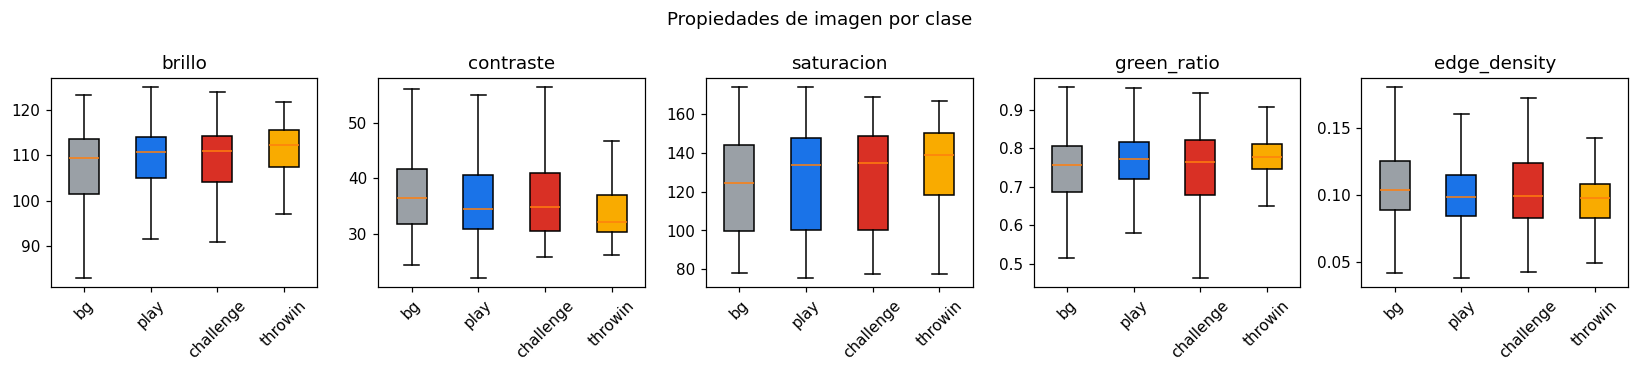

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
order = [l for l in ["bg","play","challenge","throwin"] if l in fm.label.unique()]
for ax, met in zip(axes, metrics):
    data = [fm.loc[fm.label == l, met] for l in order]
    bp = ax.boxplot(data, labels=order, patch_artist=True, showfliers=False)
    for patch, l in zip(bp["boxes"], order):
        patch.set_facecolor(PALETTE[l])
    ax.set_title(met); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Propiedades de imagen por clase")
plt.tight_layout(); plt.savefig(FIG / "04_box_propiedades_por_clase.png"); plt.show()

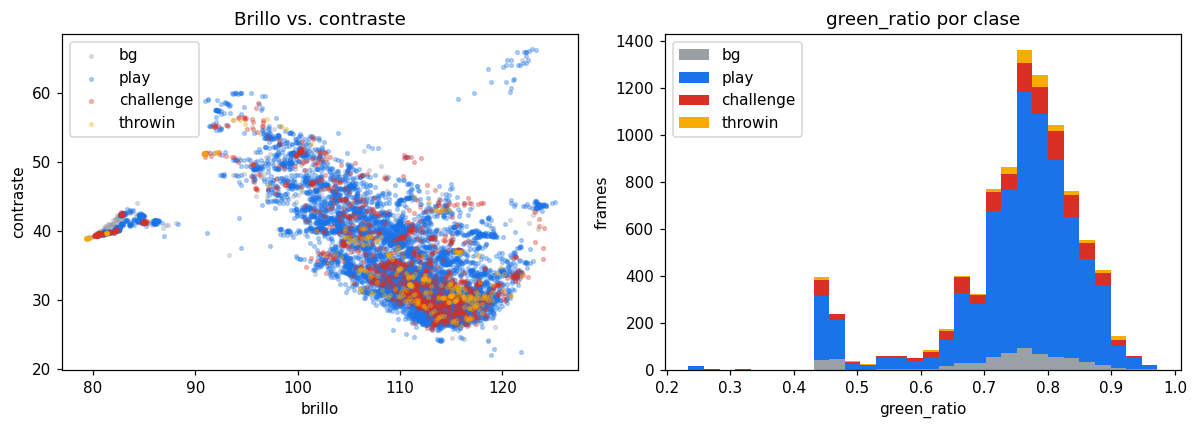

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for l in order:
    s = fm[fm.label == l]
    ax[0].scatter(s.brillo, s.contraste, s=6, alpha=.3, label=l, color=PALETTE[l])
ax[0].set_xlabel("brillo"); ax[0].set_ylabel("contraste"); ax[0].legend()
ax[0].set_title("Brillo vs. contraste")

ax[1].hist([fm.loc[fm.label == l, "green_ratio"] for l in order], bins=30,
           stacked=True, color=[PALETTE[l] for l in order], label=order)
ax[1].set_xlabel("green_ratio"); ax[1].set_ylabel("frames"); ax[1].legend()
ax[1].set_title("green_ratio por clase")
plt.tight_layout(); plt.savefig(FIG / "05_scatter_brillo_green.png"); plt.show()

## 5. Tipo de plano / cámara

`green_ratio` alto ⇒ plano general; bajo ⇒ replay / primer plano. Umbral `THR_GREEN`.

In [ ]:
THR_GREEN = 0.30  # ajustar según el histograma de la sección 4
fm["plano"] = np.where(fm.green_ratio >= THR_GREEN, "general", "primer_plano/replay")

print("Proporción de frames por tipo de plano:")
print((fm.plano.value_counts(normalize=True) * 100).round(1))

print("\nTipo de plano por clase (%):")
print((fm.groupby("label").plano.value_counts(normalize=True).unstack().fillna(0) * 100).round(1))

# ¿los eventos puntuales caen en plano general?
pe = fm[fm.label.isin(POINT)]
print(f"\nEventos puntuales en plano general: {(pe.plano == 'general').mean()*100:.1f}%")

Proporción de frames por tipo de plano:
plano
general                99.8
primer_plano/replay     0.2
Name: proportion, dtype: float64

Tipo de plano por clase (%):
plano      general  primer_plano/replay
label                                  
bg            99.8                  0.2
challenge    100.0                  0.0
play          99.7                  0.3
throwin      100.0                  0.0

Eventos puntuales en plano general: 99.8%


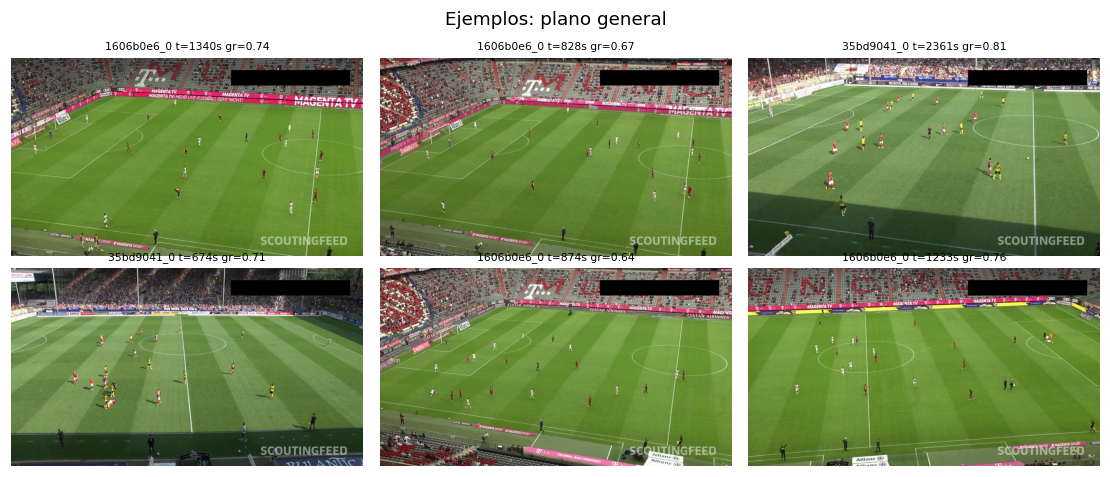

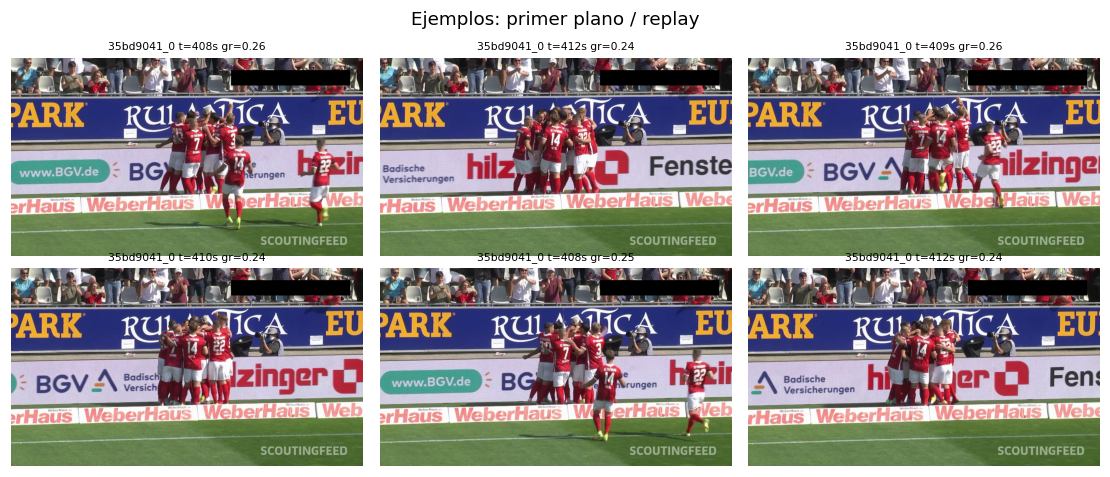

In [ ]:
def montage(df_sel, title, fname, n=6, cols=3):
    df_sel = df_sel.head(n)
    rows_ = max(1, int(np.ceil(len(df_sel) / cols)))
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 3.4, rows_ * 2.2))
    axflat = np.ravel(axes)
    for ax, r in zip(axflat, df_sel.itertuples(index=False)):
        img = cv2.imread(str(PROJECT_DIR / r.path))
        if img is None:
            ax.axis("off"); continue
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        gr = getattr(r, "green_ratio", None)
        extra = f" gr={gr:.2f}" if gr is not None else ""
        ax.set_title(f"{r.video_id} t={r.time_s:.0f}s{extra}", fontsize=7)
        ax.axis("off")
    for ax in axflat[len(df_sel):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout(); plt.savefig(FIG / fname); plt.show()


montage(fm[fm.plano == "general"].sample(min(6, int((fm.plano == "general").sum())), random_state=1),
        "Ejemplos: plano general", "06_plano_general.png")
montage(fm[fm.plano != "general"].sample(min(6, int((fm.plano != "general").sum())), random_state=1),
        "Ejemplos: primer plano / replay", "07_primer_plano.png")

## 6. Movimiento alrededor del evento

Proxy = diferencia media absoluta entre frames consecutivos de la ventana.

In [ ]:
def gray_small(path):
    img = cv2.imread(str(PROJECT_DIR / path))
    if img is None:
        return None
    h, w = img.shape[:2]
    return cv2.cvtColor(cv2.resize(img, (160, int(160 * h / w))), cv2.COLOR_BGR2GRAY).astype(np.int16)

# movimiento por frame 'bg': diff con el frame bg anterior del mismo video
bg = frames_index[frames_index.label == "bg"].sort_values(["video_id", "time_s"])
bg_motion = []
for vid, g in bg.groupby("video_id"):
    prev = None
    for r in g.itertuples(index=False):
        cur = gray_small(r.path)
        if cur is not None and prev is not None and prev.shape == cur.shape:
            bg_motion.append(np.abs(cur - prev).mean())
        prev = cur
bg_motion = np.array(bg_motion)
print(f"movimiento bg: media {bg_motion.mean():.2f}")

movimiento bg: media 19.31


In [ ]:
# movimiento en la ventana de cada evento puntual, normalizado por el gap temporal real
ev = events[events.is_point_event].copy()
fi_pt = frames_index[frames_index.label.isin(POINT)]

recs = []
for e in ev.itertuples(index=False):
    win = fi_pt[(fi_pt.video_id == e.video_id) &
               (fi_pt.time_s.between(e.time_s - 2.05, e.time_s + 2.05))].sort_values("time_s")
    frs = [(t, gray_small(p)) for t, p in zip(win.time_s, win.path)]
    frs = [(t, a) for t, a in frs if a is not None]
    for (t0, a0), (t1, a1) in zip(frs, frs[1:]):
        if a0.shape == a1.shape and 0.05 < t1 - t0 < 1.0:
            recs.append({"event": e.event,
                         "offset": round((t0 + t1) / 2 - e.time_s, 1),
                         "motion": float(np.abs(a1 - a0).mean()) / (t1 - t0)})
mv = pd.DataFrame(recs)
mv["abs_offset"] = mv.offset.abs().round().clip(upper=2)
print(mv.groupby("event").motion.describe().round(1))

            count  mean   std  min   25%   50%   75%    max
event                                                      
challenge  1280.0  32.4  24.3  2.8  19.0  27.6  39.2  195.2
play       8955.0  30.1  22.5  2.9  16.3  25.1  36.8  266.2
throwin     340.0  27.1  19.4  3.2  15.5  24.9  32.9  134.1


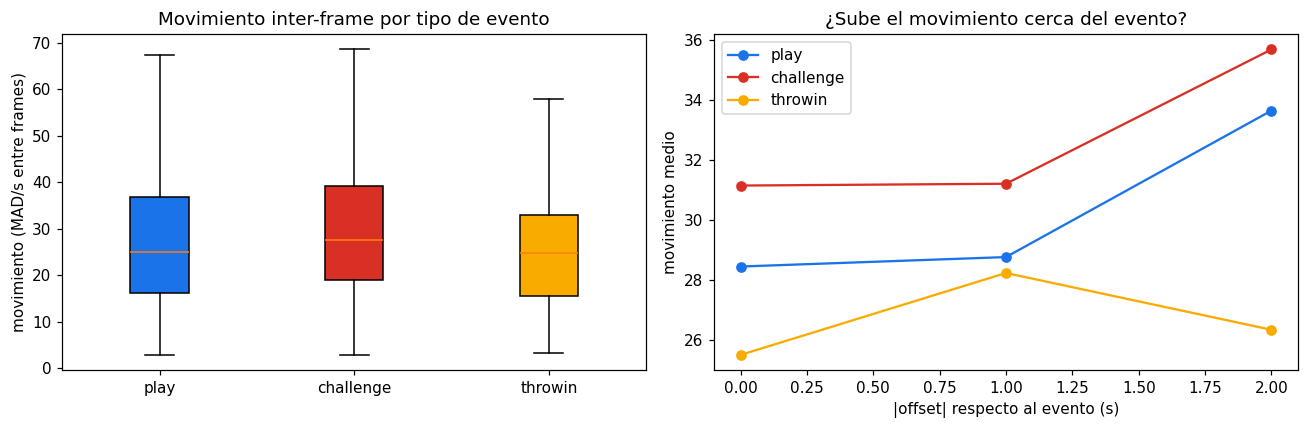

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

order = [l for l in ["play", "challenge", "throwin"] if l in mv.event.unique()]
bp = ax[0].boxplot([mv.loc[mv.event == l, "motion"] for l in order],
                   labels=order, patch_artist=True, showfliers=False)
for patch, l in zip(bp["boxes"], order):
    patch.set_facecolor(PALETTE[l])
ax[0].set_ylabel("movimiento (MAD/s entre frames)")
ax[0].set_title("Movimiento inter-frame por tipo de evento")

for l in order:
    curve = mv[mv.event == l].groupby("abs_offset").motion.mean()
    ax[1].plot(curve.index, curve.values, marker="o", label=l, color=PALETTE[l])
ax[1].set_xlabel("|offset| respecto al evento (s)"); ax[1].set_ylabel("movimiento medio")
ax[1].set_title("¿Sube el movimiento cerca del evento?"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "08_movimiento.png"); plt.show()

## 7. Galería de ejemplos por tipo de evento (t ≈ 0)

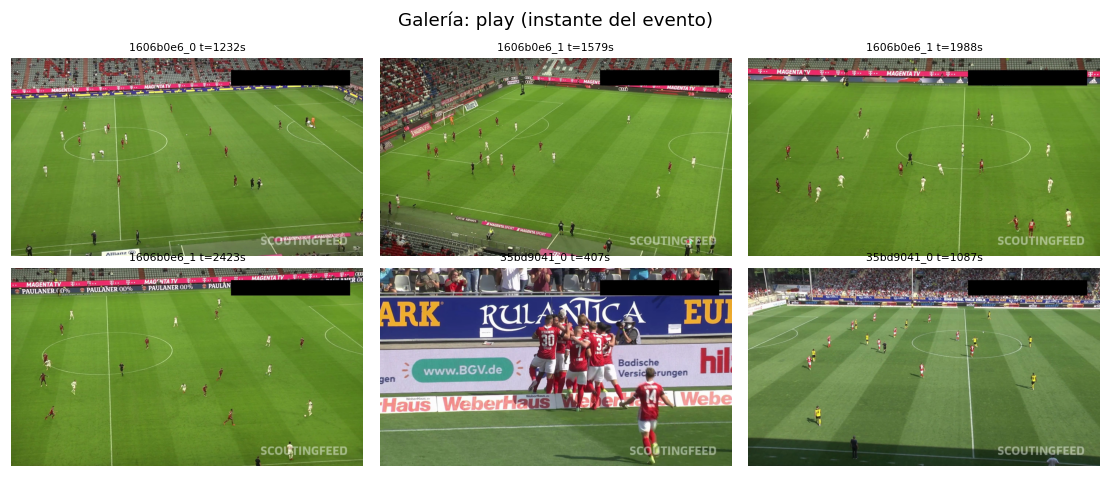

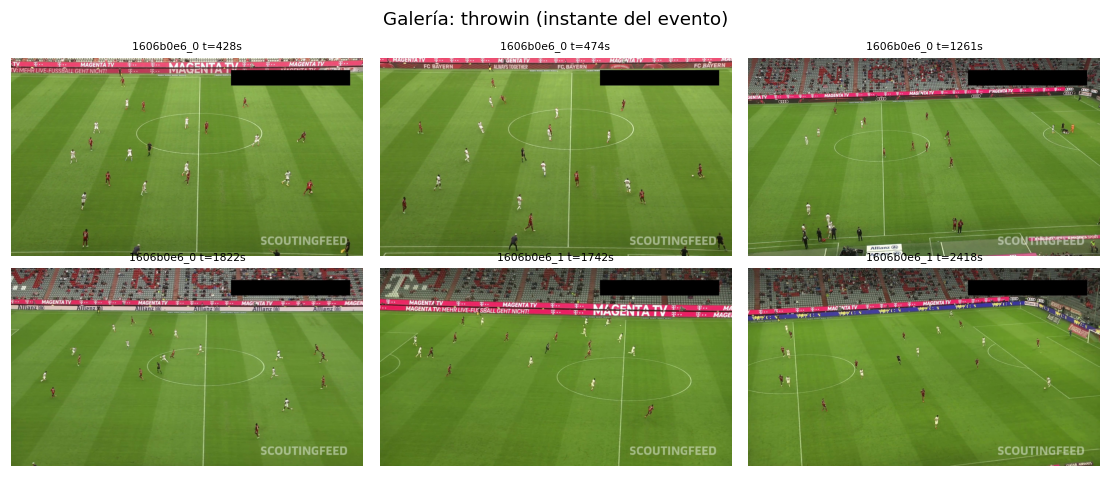

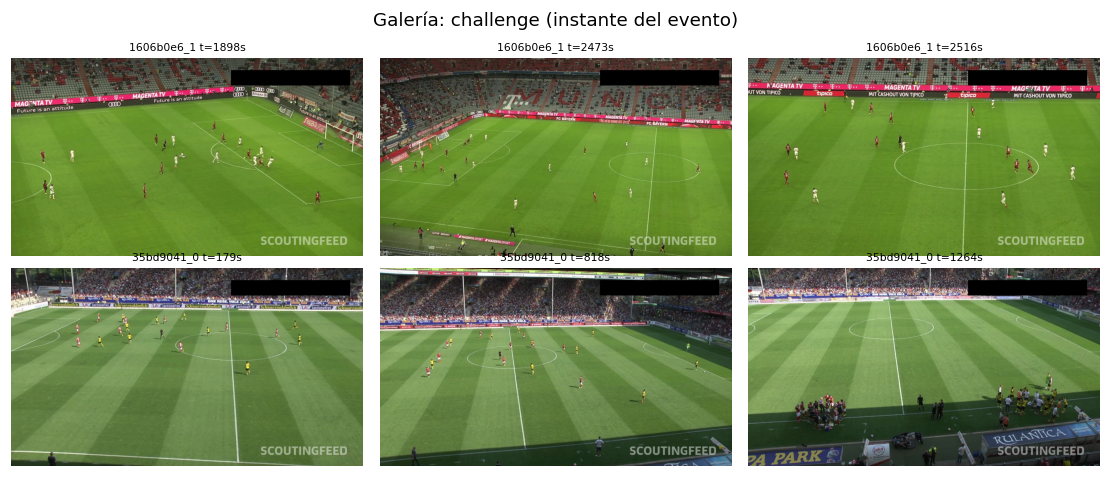

In [ ]:
# para cada evento puntual, el frame muestreado más cercano a su instante (offset ~0)
gal_rows = []
for e in events[events.is_point_event].itertuples(index=False):
    w = fi_pt[fi_pt.video_id == e.video_id]
    if w.empty:
        continue
    j = (w.time_s - e.time_s).abs().idxmin()
    if abs(w.loc[j, "time_s"] - e.time_s) <= 0.6:
        gal_rows.append({"video_id": e.video_id, "time_s": w.loc[j, "time_s"],
                         "label": e.event, "path": w.loc[j, "path"]})
gallery = pd.DataFrame(gal_rows)

for evt in POINT:
    sub = gallery[gallery.label == evt]
    if sub.empty:
        print("sin frames para", evt); continue
    montage(sub.sample(min(6, len(sub)), random_state=7).sort_values(["video_id", "time_s"]),
            f"Galería: {evt} (instante del evento)", f"09_galeria_{evt}.png")

## 8. Outliers y valores faltantes visuales

frames muy oscuros (p1): 92 | muy claros (p99): 92
frames ilegibles: 0

saltos de movimiento bg > p99 (40.8): 7 (posibles cambios de cámara/repetición)

Videos anotados SIN footage disponible:
  video_id  n_events
3c993bd2_1       966
407c5a9e_1       858
4ffd5986_0       792
9a97dae4_1       737
cfbe2e94_0       823
cfbe2e94_1       763
ecf251d4_0       980
=> 7/12 videos sin video: 5919 eventos.

Videos con footage (truncados a su prefijo):
  1606b0e6_0: 293 eventos con imagen, 103 sin imagen (video hasta t=2280s)
  1606b0e6_1: 381 eventos con imagen, 126 sin imagen (video hasta t=2760s)
  35bd9041_0: 312 eventos con imagen, 99 sin imagen (video hasta t=2490s)
  35bd9041_1: 293 eventos con imagen, 66 sin imagen (video hasta t=2790s)
  3c993bd2_0: 335 eventos con imagen, 79 sin imagen (video hasta t=2430s)
=> 473 eventos puntuales adicionales sin footage por truncamiento.


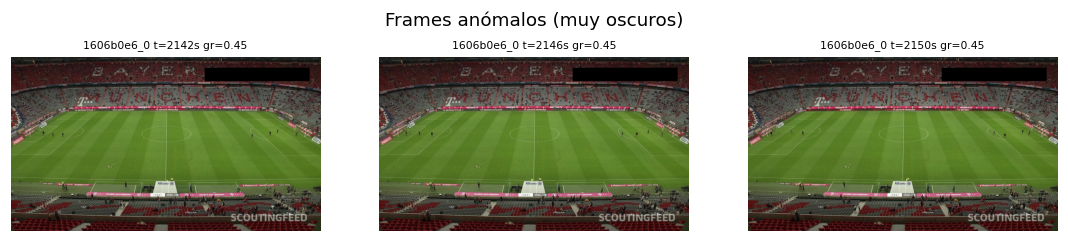

In [ ]:
dark = fm[fm.brillo < fm.brillo.quantile(0.01)]
blown = fm[fm.brillo > fm.brillo.quantile(0.99)]
print(f"frames muy oscuros (p1): {len(dark)} | muy claros (p99): {len(blown)}")
print(f"frames ilegibles: {len(frames_index) - len(fm)}")

# posibles cortes de escena: saltos grandes de movimiento entre frames bg consecutivos
print(f"\nsaltos de movimiento bg > p99 ({np.quantile(bg_motion,0.99):.1f}): "
      f"{(bg_motion > np.quantile(bg_motion, 0.99)).sum()} (posibles cambios de cámara/repetición)")

# --- cobertura de video ---
print("\nVideos anotados SIN footage disponible:")
print(video_meta.loc[~video_meta.has_video, ["video_id", "n_events"]].to_string(index=False))
print(f"=> {(~video_meta.has_video).sum()}/12 videos sin video: "
      f"{video_meta.loc[~video_meta.has_video,'n_events'].sum()} eventos.")

# los videos con footage están truncados a su prefijo
pe = events[events.is_point_event]
last_s = clip_index.groupby("video_id").clip_num.max() * 30
trunc = {v: int((pe[pe.video_id == v].time_s >= last_s[v]).sum()) for v in last_s.index}
cov = {v: int((pe[pe.video_id == v].time_s < last_s[v]).sum()) for v in last_s.index}
print("\nVideos con footage (truncados a su prefijo):")
for v in last_s.index:
    print(f"  {v}: {cov[v]} eventos con imagen, {trunc[v]} sin imagen (video hasta t={int(last_s[v])}s)")
print(f"=> {sum(trunc.values())} eventos puntuales adicionales sin footage por truncamiento.")

if len(dark):
    montage(dark.head(3), "Frames anómalos (muy oscuros)", "10_outliers_oscuros.png", n=3)

## 9. Densidad de objetos sobre el campo

HOG de OpenCV como referencia (falla: jugadores demasiado pequeños) + proxy de blobs
no-verdes del tamaño de un jugador dentro de la franja del campo.

In [ ]:
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

def count_people_hog(path):
    img = cv2.imread(str(PROJECT_DIR / path))
    if img is None:
        return np.nan
    h, w = img.shape[:2]
    img = cv2.resize(img, (512, int(512 * h / w)))
    rects, _ = hog.detectMultiScale(img, winStride=(16, 16), padding=(8, 8), scale=1.1)
    return len(rects)


def field_blobs(path):
    """Blobs no-verdes de tamaño ~jugador dentro de la franja del campo."""
    img = cv2.imread(str(PROJECT_DIR / path))
    if img is None:
        return np.nan
    h, w = img.shape[:2]
    img = cv2.resize(img, (480, int(480 * h / w)))
    green = cv2.inRange(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), GREEN_LO, GREEN_HI)
    row_has_field = green.mean(axis=1) > 30
    if row_has_field.sum() < 5:
        return np.nan
    y0 = np.argmax(row_has_field)
    y1 = len(row_has_field) - np.argmax(row_has_field[::-1])
    band = cv2.morphologyEx(255 - green[y0:y1], cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    _, _, stats, _ = cv2.connectedComponentsWithStats(band)
    areas = stats[1:, cv2.CC_STAT_AREA]
    return int(((areas >= 8) & (areas <= 400)).sum())


n_per = min(50, int(frames_index.label.value_counts().min()))
sample = (frames_index.groupby("label").sample(n=n_per, random_state=3)
          .reset_index(drop=True))
sample = sample.merge(fm[["path", "plano"]], on="path", how="left")
sample["hog_people"] = sample.path.apply(count_people_hog)
sample["field_blobs"] = sample.path.apply(field_blobs)

print("frames por clase en la submuestra:", n_per)
print("HOG - total de personas detectadas en toda la submuestra:", int(sample.hog_people.sum()))
print("\nblobs tipo jugador por clase:")
print(sample.groupby("label").field_blobs.describe().round(1))

frames por clase en la submuestra: 50
HOG - total de personas detectadas en toda la submuestra: 0

blobs tipo jugador por clase:
           count  mean  std   min   25%   50%   75%   max
label                                                    
bg          50.0  31.2  7.9  13.0  25.2  31.5  37.0  46.0
challenge   50.0  30.3  9.1  14.0  23.0  30.0  35.8  53.0
play        50.0  28.4  9.5  12.0  22.0  27.0  35.0  62.0
throwin     50.0  30.9  7.9  16.0  25.0  31.5  37.2  47.0


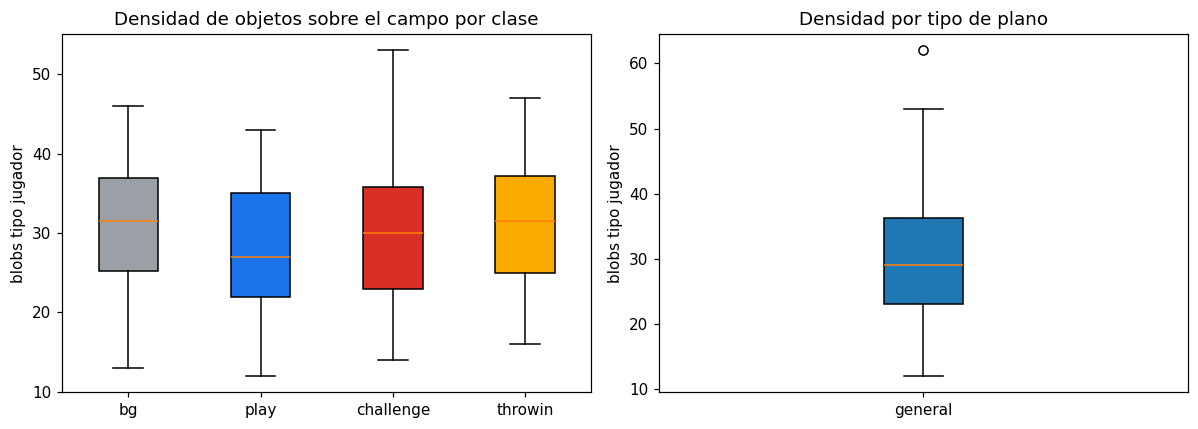

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = [l for l in ["bg", "play", "challenge", "throwin"] if l in sample.label.unique()]
d = [sample.loc[sample.label == l, "field_blobs"].dropna() for l in order]
bp = ax[0].boxplot(d, labels=order, patch_artist=True, showfliers=False)
for patch, l in zip(bp["boxes"], order):
    patch.set_facecolor(PALETTE[l])
ax[0].set_ylabel("blobs tipo jugador"); ax[0].set_title("Densidad de objetos sobre el campo por clase")

if sample.plano.notna().any():
    planos = [p for p in ["general", "primer_plano/replay"] if (sample.plano == p).any()]
    d2 = [sample.loc[sample.plano == p, "field_blobs"].dropna() for p in planos]
    ax[1].boxplot(d2, labels=planos, patch_artist=True)
    ax[1].set_ylabel("blobs tipo jugador"); ax[1].set_title("Densidad por tipo de plano")
plt.tight_layout(); plt.savefig(FIG / "11_densidad_objetos.png"); plt.show()